Cell 1

In [146]:
import os
import sys

# Define your local data root directory
DATA_DIR = r"data"

# Clone SpikerTools locally if it doesn't exist in your workspace
if not os.path.isdir("SpikerTools"):
    # Pylance will complain about ! but it works at runtime
    !git clone https://github.com/BackyardBrains/SpikerTools.git
    %cd SpikerTools
    %pip install -e.
    %cd..
else:
    print("SpikerTools already detected locally.")

# Force Python to look into your local SpikerTools folder
sys.path.append(os.path.abspath("./SpikerTools"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spikertools as sp
from scipy.io import wavfile

print("\nSuccess! Environment configured and Spikertools is loaded.")

SpikerTools already detected locally.

Success! Environment configured and Spikertools is loaded.


Cell 2

In [147]:
def search_directory(directory):
    for root, dirs, files in os.walk(directory):
        for file in files:
            if file.endswith(".wav"):
                full_path = os.path.join(root, file)

                # Get the path relative to the main Data folder
                relative_path = os.path.relpath(root, directory)
                path_parts = relative_path.split(os.sep)

                # Handle case where we're in the root data dir: relative_path = '.'
                if relative_path == '.':
                    location = subject = session = 'N/A'
                else:
                    # Dynamic mapping: Data / Location / Subject / Session
                    location = path_parts[0] if len(path_parts) > 0 else 'N/A'
                    subject = path_parts[1] if len(path_parts) > 1 else 'N/A' # Fixed: > 1
                    session = path_parts[2] if len(path_parts) > 2 else 'N/A'

                wav_file = file
                txt_file_found = False

                for txt_file in files:
                    if txt_file.endswith(".txt") and wav_file[:-4] in txt_file:
                        txt_file_found = True
                        yield location, subject, session, wav_file, txt_file, full_path
                        break # Stop after finding first match

                if not txt_file_found:
                    yield location, subject, session, wav_file, 'N/A', full_path

wav_files = list(search_directory(DATA_DIR))

data = {
    'Location': [item[0] for item in wav_files],
    'Subject': [item[1] if item[1]!= '' else 'N/A' for item in wav_files],
    'Session': [item[2] if item[2]!= '' else 'N/A' for item in wav_files],
    'Recording': [item[3] for item in wav_files],
    'Events': [item[4] for item in wav_files],
    'Path': [item[5] for item in wav_files]
}

df_files = pd.DataFrame(data)
print("Number of.wav files found across all subjects:", len(wav_files))
df_files

Number of.wav files found across all subjects: 154


,Location,Subject,Session,Recording,Events,Path
0,Fatigue,S01,N/A,13.1 F.wav,13.1 F-events.txt,data\al ...
1,Fatigue,S01,N/A,13.2 F.wav,13.2 F-events.txt,data\al ...
2,Fatigue,S01,N/A,13.3 F.wav,13.3 F-events.txt,data\al ...
3,Fatigue,S01,N/A,13.4 F.wav,13.4 F-events.txt,data\al ...
4,Fatigue,S01,N/A,13.5 F.wav,13.5 F-events.txt,data\al ...
...,...,...,...,...,...,...
149,Non Fatigue,S14,N/A,12.1 NF.wav,12.1 NF-events.txt,data\al ...
150,Non Fatigue,S14,N/A,12.2 NF.wav,12.2 NF-events.txt,data\al ...
151,Non Fatigue,S14,N/A,12.3 NF.wav,12.3 NF-events.txt,data\al ...
152,Non Fatigue,S14,N/A,12.4 NF.wav,12.4 NF-events.txt,data\al ...


Cell 3

In [148]:
import os

for folder in ['Fatigue', 'Non Fatigue', 'Induce']:
    path = os.path.join(DATA_DIR, folder)
    if os.path.exists(path):
        for root, dirs, files in os.walk(path):
            for filename in files:
                # Target un-renamed text files
                if filename.endswith(".txt") and "-events" not in filename:
                    old_file = os.path.join(root, filename)
                    new_file = os.path.join(root, filename.replace(".txt", "-events.txt"))
                    
                    os.rename(old_file, new_file)
                    
                    # Extract subject name and clean filename for readable confirmation logs
                    subject_name = os.path.basename(root)
                    print(f"Renamed [{subject_name}]: {filename} -> {os.path.basename(new_file)}")
                    
print("\nRenaming check complete. All subjects' event files are standardized!")


Renaming check complete. All subjects' event files are standardized!


Final preprocessing logic, CELL 4 — FEATURE EXTRACTION

In [149]:
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt
from scipy.fft import rfft, rfftfreq
import os

# ---------- FILTERS ----------
def bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut / nyq, highcut / nyq], btype='band')
    return filtfilt(b, a, data)

def moving_rms(x, window_samples):
    return np.sqrt(np.convolve(x**2, np.ones(window_samples)/window_samples, mode='same'))

# ---------- ADAPTIVE BURST DETECTOR ----------
def detect_adaptive_bursts(
    y_env,
    fs,
    percentile=80,
    min_duration_s=0.5,
    merge_gap_s=0.2
):

    # percentile threshold
    thresh = np.percentile(y_env, percentile)

    active = y_env > thresh

    # bridge tiny gaps
    gap_samples = int(0.05 * fs)

    for i in range(1, len(active) - gap_samples):
        if not active[i]:
            if active[i - 1] and np.any(active[i:i + gap_samples]):
                active[i:i + gap_samples] = True

    diff = np.diff(active.astype(int))

    starts = np.where(diff == 1)[0] + 1
    ends = np.where(diff == -1)[0] + 1

    if active[0]:
        starts = np.insert(starts, 0, 0)

    if active[-1]:
        ends = np.append(ends, len(active)-1)

    if len(starts) == 0:
        return []

    # remove short bursts
    min_samples = int(min_duration_s * fs)

    valid = (ends - starts) >= min_samples

    starts = starts[valid]
    ends = ends[valid]

    # merge close bursts
    merge_samples = int(merge_gap_s * fs)

    merged = []

    if len(starts) > 0:

        cur_start = starts[0]
        cur_end = ends[0]

        for s, e in zip(starts[1:], ends[1:]):

            if s - cur_end <= merge_samples:
                cur_end = e
            else:
                merged.append((cur_start, cur_end))
                cur_start, cur_end = s, e

        merged.append((cur_start, cur_end))

    return merged

# ---------- ENHANCED FEATURES ----------
def compute_spectral_entropy(signal, fs):
    yf = np.abs(rfft(signal))
    xf = rfftfreq(len(signal), 1/fs)
    mask = (xf >= 20) & (xf <= 450)
    psd = yf**2
    psd = psd / (np.sum(psd) + 1e-8)
    return -np.sum(psd * np.log2(psd + 1e-8))

def compute_zc(signal, threshold=1e-5):
    # Zero crossings
    return np.sum(np.diff(np.signbit(signal - threshold))!= 0)

def compute_ssc(signal, threshold=1e-5):
    # Slope sign changes
    diff = np.diff(signal)
    return np.sum(np.diff(np.signbit(diff - threshold))!= 0)

def compute_wl(signal):
    # Waveform length
    return np.sum(np.abs(np.diff(signal)))

def extract_window_features(window, fs):
    """Extract 10 features from one EMG window"""
    # Time domain
    mav = np.mean(np.abs(window))
    rms = np.sqrt(np.mean(window**2))
    wl = compute_wl(window)
    zc = compute_zc(window)
    ssc = compute_ssc(window)
    iemg = np.sum(np.abs(window))

    # Frequency domain
    yf = np.abs(rfft(window))
    xf = rfftfreq(len(window), 1/fs)
    mask = (xf >= 20) & (xf <= 450)
    yf = yf[mask]
    xf = xf[mask]

    if np.sum(yf) < 1e-8:
        mnf, mdf, se = 0.0, 0.0, 0.0
        peak_freq = 0.0
    else:
        mnf = np.sum(xf * yf) / np.sum(yf)
        cumsum = np.cumsum(yf)
        mdf = xf[np.where(cumsum >= cumsum[-1] / 2)[0][0]]
        se = compute_spectral_entropy(window, fs)
        peak_freq = xf[np.argmax(yf)]

    return {
        'MAV': mav, 'RMS': rms, 'WL': wl, 'ZC': zc, 'SSC': ssc, 'IEMG': iemg,
        'MNF': mnf, 'MDF': mdf, 'SE': se, 'PeakFreq': peak_freq
    }

def sliding_window_features(segment, fs, win_s=0.25, overlap=0.5):
    """Split burst into overlapping windows and extract features per window"""
    win_samples = int(win_s * fs)
    step = int(win_samples * (1 - overlap))

    features_list = []
    for start in range(0, len(segment) - win_samples + 1, step):
        win = segment[start:start + win_samples]
        feats = extract_window_features(win, fs)
        feats['WinStart'] = start / fs # time within burst
        features_list.append(feats)

    return features_list

CELL 5 — BURST PIPELINE

In [150]:
import spikertools as sp

all_windows = []
total_bursts = 0

WIN_S = 0.25 # 250 ms windows
OVERLAP = 0.5 # 50% overlap
MIN_BURST_S = 0.5 # discard bursts < 0.5s

print("=== ADAPTIVE PIPELINE + SLIDING WINDOWS ===")

for i, file_path_val in enumerate(df_files.Path.values):
    if not file_path_val.endswith(".wav"):
        continue

    try:
        MySession = sp.Session(file_path_val)
        MyChannel = MySession.channels[0]
        fs = getattr(MyChannel, 'fs', getattr(MySession, 'sample_rate', 5000))

        y_raw = getattr(MyChannel, 'data', None)
        if y_raw is None: y_raw = MyChannel.get_data()

        # 1. Preprocess: 20-450 Hz bandpass + rectify + smooth RMS
        y_bp = bandpass_filter(y_raw, 20, 450, fs)
        y_rect = np.abs(y_bp)
        y_env = moving_rms(y_rect, int(0.05 * fs)) # 50ms RMS

        subject = df_files.Subject.values[i]
        location = df_files.Location.values[i].strip()
        label = 1 if location == "Fatigue" else 0

        # 2. Adaptive burst detection on whole file
        bursts = detect_adaptive_bursts(y_env, fs, percentile=80, min_duration_s=MIN_BURST_S)
        total_bursts += len(bursts)
        print(f"{os.path.basename(file_path_val)} | bursts: {len(bursts)}")

        # 3. For each burst, do sliding windows
        for b_idx, (s, e) in enumerate(bursts):
            seg = y_bp[s:e] # use bandpassed signal for features
            if len(seg) < int(WIN_S * fs): continue

            win_feats = sliding_window_features(seg, fs, win_s=WIN_S, overlap=OVERLAP)

            for w_idx, feats in enumerate(win_feats):
                feats.update({
                    'Subject': subject,
                    'Location': location,
                    'Label': label,
                    'BurstIdx': b_idx,
                    'WindowIdx': w_idx,
                    'File': os.path.basename(file_path_val)
                })
                all_windows.append(feats)

    except Exception as e:
        print("Error:", file_path_val, e)

features_df = pd.DataFrame(all_windows)
print("\n=== DONE ===")
print("Total bursts:", total_bursts)
print("Total windows:", len(features_df))
if not features_df.empty:
    print(features_df['Label'].value_counts())

=== ADAPTIVE PIPELINE + SLIDING WINDOWS ===
Loaded WAV file: data\Fatigue\S01\13.1 F.wav
Sample rate: 5000 Hz
Data length: 297647 samples
Looking for events file: data\Fatigue\S01\13.1 F-events.txt
Loaded 1 events and 0 neurons.
13.1 F.wav | bursts: 8
Loaded WAV file: data\Fatigue\S01\13.2 F.wav
Sample rate: 5000 Hz
Data length: 297583 samples
Looking for events file: data\Fatigue\S01\13.2 F-events.txt
Loaded 1 events and 0 neurons.
13.2 F.wav | bursts: 6
Loaded WAV file: data\Fatigue\S01\13.3 F.wav
Sample rate: 5000 Hz
Data length: 298661 samples
Looking for events file: data\Fatigue\S01\13.3 F-events.txt
Loaded 1 events and 0 neurons.
13.3 F.wav | bursts: 7
Loaded WAV file: data\Fatigue\S01\13.4 F.wav
Sample rate: 5000 Hz
Data length: 303163 samples
Looking for events file: data\Fatigue\S01\13.4 F-events.txt
Loaded 1 events and 0 neurons.
13.4 F.wav | bursts: 9
Loaded WAV file: data\Fatigue\S01\13.5 F.wav
Sample rate: 5000 Hz
Data length: 303077 samples
Looking for events file: data\

cell 6

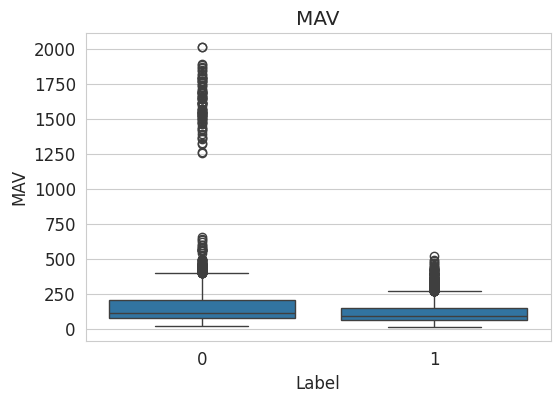

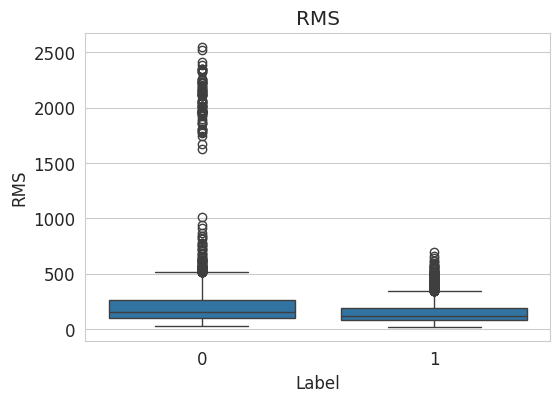

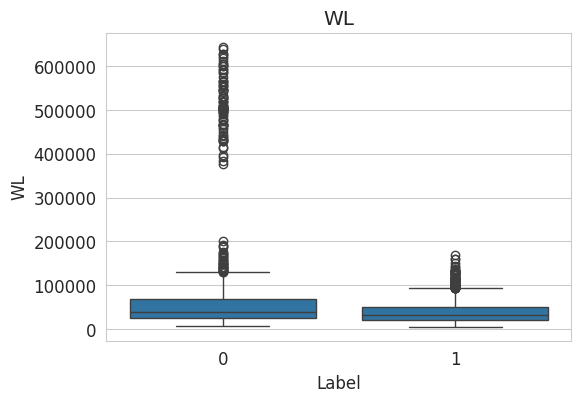

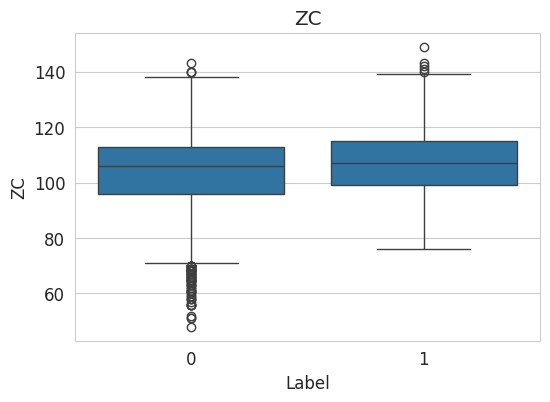

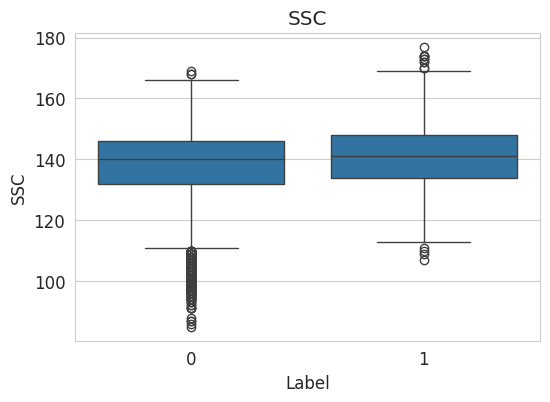

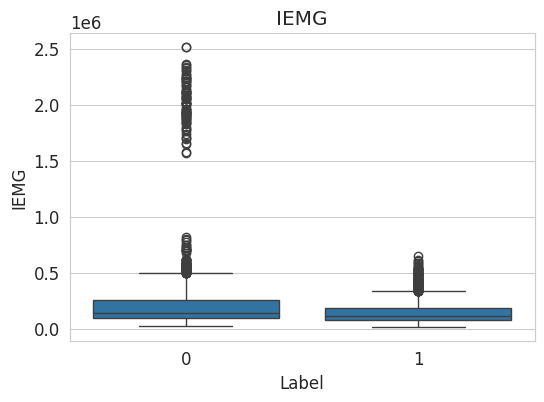

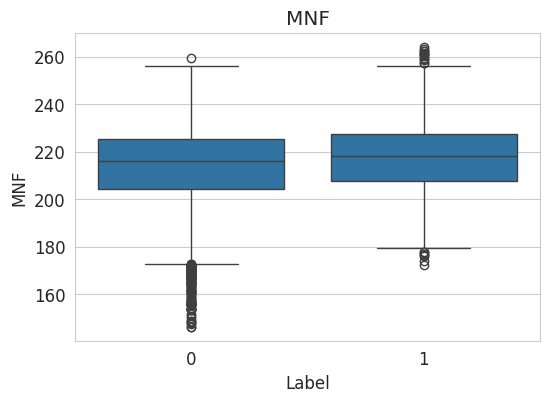

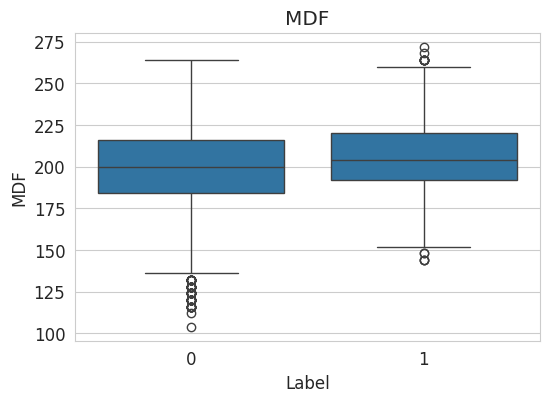

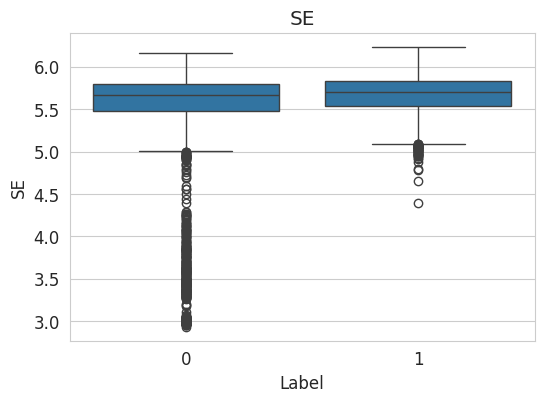

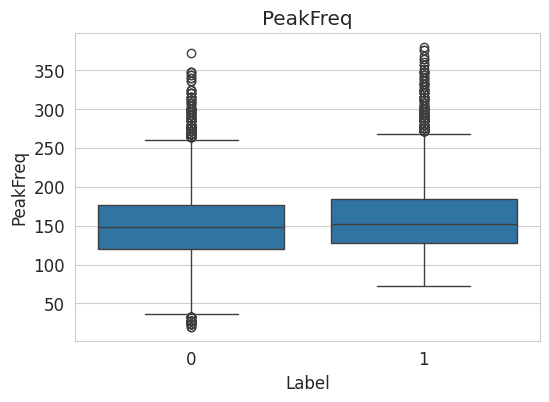

In [151]:
import seaborn as sns
import matplotlib.pyplot as plt

feat_cols = [
    'MAV', 'RMS', 'WL', 'ZC', 'SSC',
    'IEMG', 'MNF', 'MDF', 'SE', 'PeakFreq'
]
for col in feat_cols:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        data=features_df,
        x='Label',
        y=col
    )

    plt.title(col)
    plt.show()

cell 7

In [152]:
import numpy as np
import pandas as pd

feat_cols = ['MAV','RMS','WL','ZC','SSC','IEMG','MNF','MDF','SE','PeakFreq']

if features_df.empty:
    print("ERROR: features_df is empty. Fix Cell 2 first.")
else:
    print("=== BOXPLOT EQUIVALENT STATS ===")
    print(f"Total windows: {len(features_df)} | Fatigue=1: {sum(features_df['Label']==1)} | NonFatigue=0: {sum(features_df['Label']==0)}")
    print(f"Subjects: {features_df['Subject'].nunique()} | Files: {features_df['File'].nunique()}")
    print("="*80)

    for col in feat_cols:
        print(f"\n### FEATURE: {col}")

        for label in [0, 1]:
            data = features_df[features_df['Label']==label][col].dropna()
            if len(data) == 0:
                print(f"Label {label}: No data")
                continue

            q1 = np.percentile(data, 25)
            median = np.percentile(data, 50)
            q3 = np.percentile(data, 75)
            iqr = q3 - q1
            lower_whisker = data[data >= q1 - 1.5*iqr].min()
            upper_whisker = data[data <= q3 + 1.5*iqr].max()
            outliers = data[(data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr)]

            label_name = "NonFatigue" if label == 0 else "Fatigue"
            print(f"\nLabel {label} = {label_name} | n={len(data)}")
            print(f" Mean: {data.mean():.4f} | Std: {data.std():.4f}")
            print(f" Min: {data.min():.4f} | Max: {data.max():.4f}")
            print(f" Q1: {q1:.4f} | Median: {median:.4f} | Q3: {q3:.4f} | IQR: {iqr:.4f}")
            print(f" Whiskers: [{lower_whisker:.4f}, {upper_whisker:.4f}]")
            print(f" Outliers: {len(outliers)} points | Max outlier: {outliers.max():.4f}" if len(outliers)>0 else " Outliers: 0")

        # Effect size check: does median differ?
        nf_med = np.percentile(features_df[features_df['Label']==0][col], 50)
        f_med = np.percentile(features_df[features_df['Label']==1][col], 50)
        pct_diff = 100 * (f_med - nf_med) / (nf_med + 1e-8)
        print(f"\n >> Median shift Fatigue vs NonFatigue: {pct_diff:+.1f}%")
        print("-"*80)

=== BOXPLOT EQUIVALENT STATS ===
Total windows: 9540 | Fatigue=1: 4335 | NonFatigue=0: 5205
Subjects: 14 | Files: 154

### FEATURE: MAV

Label 0 = NonFatigue | n=5205
 Mean: 172.0910 | Std: 210.4504
 Min: 17.5644 | Max: 2014.7605
 Q1: 76.7602 | Median: 115.1323 | Q3: 205.1459 | IQR: 128.3858
 Whiskers: [17.5644, 396.2429]
 Outliers: 237 points | Max outlier: 2014.7605

Label 1 = Fatigue | n=4335
 Mean: 116.6124 | Std: 75.7786
 Min: 15.4283 | Max: 517.6900
 Q1: 64.1403 | Median: 93.6083 | Q3: 145.8439 | IQR: 81.7036
 Whiskers: [15.4283, 268.3743]
 Outliers: 242 points | Max outlier: 517.6900

 >> Median shift Fatigue vs NonFatigue: -18.7%
--------------------------------------------------------------------------------

### FEATURE: RMS

Label 0 = NonFatigue | n=5205
 Mean: 221.2058 | Std: 268.6898
 Min: 22.0281 | Max: 2549.4075
 Q1: 99.7646 | Median: 149.4969 | Q3: 264.4057 | IQR: 164.6411
 Whiskers: [22.0281, 510.0159]
 Outliers: 173 points | Max outlier: 2549.4075

Label 1 = Fatigue |

cell 8- Correlation Matrix

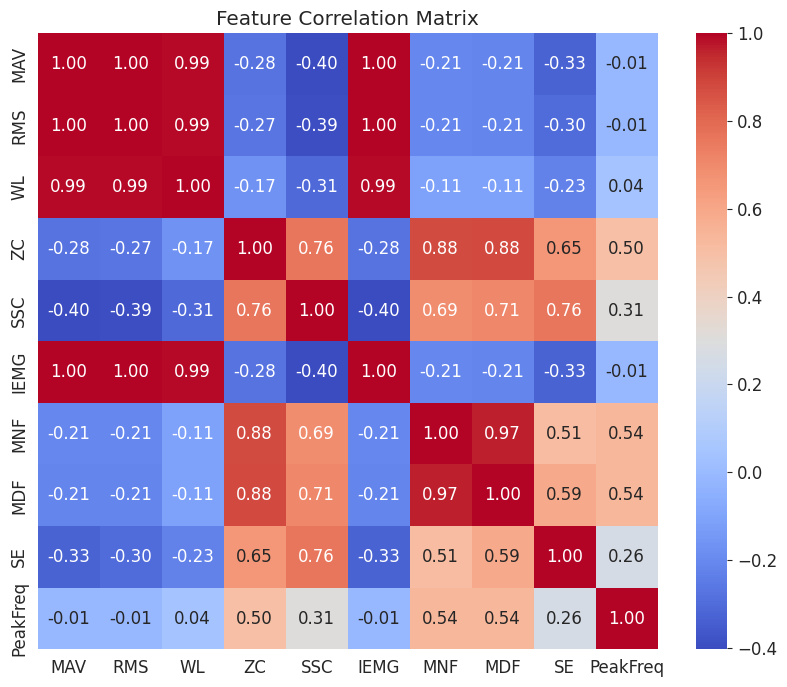


FEATURE CORRELATION MATRIX - TEXT VERSION

Full correlation matrix:
           MAV   RMS    WL    ZC   SSC  IEMG   MNF   MDF    SE  PeakFreq
MAV       1.00  1.00  0.99 -0.28 -0.40  1.00 -0.21 -0.21 -0.33     -0.01
RMS       1.00  1.00  0.99 -0.27 -0.39  1.00 -0.21 -0.21 -0.30     -0.01
WL        0.99  0.99  1.00 -0.17 -0.31  0.99 -0.11 -0.11 -0.23      0.04
ZC       -0.28 -0.27 -0.17  1.00  0.76 -0.28  0.88  0.88  0.65      0.50
SSC      -0.40 -0.39 -0.31  0.76  1.00 -0.40  0.69  0.71  0.76      0.31
IEMG      1.00  1.00  0.99 -0.28 -0.40  1.00 -0.21 -0.21 -0.33     -0.01
MNF      -0.21 -0.21 -0.11  0.88  0.69 -0.21  1.00  0.97  0.51      0.54
MDF      -0.21 -0.21 -0.11  0.88  0.71 -0.21  0.97  1.00  0.59      0.54
SE       -0.33 -0.30 -0.23  0.65  0.76 -0.33  0.51  0.59  1.00      0.26
PeakFreq -0.01 -0.01  0.04  0.50  0.31 -0.01  0.54  0.54  0.26      1.00

------------------------------------------------------------
STRONG CORRELATIONS |r| >= 0.7
-----------------------------------

In [153]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

corr = features_df[feat_cols].corr()

# 1. Plot heatmap like before
plt.figure(figsize=(10,8))
sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f')
plt.title("Feature Correlation Matrix")
plt.show()

# 2. Terminal output that describes everything in the matrix
print("\n" + "="*60)
print("FEATURE CORRELATION MATRIX - TEXT VERSION")
print("="*60)

# Print full matrix rounded to 2 decimals
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print("\nFull correlation matrix:")
print(corr.round(2))

# Print top correlated pairs to make it readable
print("\n" + "-"*60)
print("STRONG CORRELATIONS |r| >= 0.7")
print("-"*60)

# Get upper triangle only to avoid duplicates
corr_unstacked = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_pairs = corr_unstacked.stack().sort_values(ascending=False)

strong_corr = corr_pairs[abs(corr_pairs) >= 0.7]

if len(strong_corr) == 0:
    print("No feature pairs with |r| >= 0.7")
else:
    for (feat1, feat2), r in strong_corr.items():
        print(f"{feat1:20} <-> {feat2:20} : r = {r:.2f}")

print("\n" + "-"*60)
print("MODERATE CORRELATIONS 0.5 <= |r| < 0.7")
print("-"*60)

moderate_corr = corr_pairs[(abs(corr_pairs) >= 0.5) & (abs(corr_pairs) < 0.7)]
if len(moderate_corr) == 0:
    print("No feature pairs with 0.5 <= |r| < 0.7")
else:
    for (feat1, feat2), r in moderate_corr.items():
        print(f"{feat1:20} <-> {feat2:20} : r = {r:.2f}")

print("="*60 + "\n")

cell 9: Feature Importance Statistics

In [154]:
from scipy.stats import mannwhitneyu

for col in feat_cols:
    a = features_df[features_df['Label']==0][col]
    b = features_df[features_df['Label']==1][col]

    stat,p = mannwhitneyu(a,b)

    print(col, p)

MAV 5.947651091248623e-58
RMS 7.899343855697202e-57
WL 3.358759969752271e-44
ZC 1.3749780701303923e-23
SSC 5.0979000694939316e-21
IEMG 5.947651091248623e-58
MNF 1.3288064358348575e-20
MDF 2.0752142662812855e-24
SE 2.910857152799778e-19
PeakFreq 6.146104963296581e-10


cell 10: Feature Scaling

In [155]:
from sklearn.preprocessing import StandardScaler

feature_cols = [
    'MAV','RMS','WL','ZC','SSC',
    'IEMG','MNF','MDF','SE','PeakFreq'
]

X = features_df[feature_cols]
y = features_df['Label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(9540, 10)


cell 11

In [156]:
features_df.columns.tolist()

['MAV',
 'RMS',
 'WL',
 'ZC',
 'SSC',
 'IEMG',
 'MNF',
 'MDF',
 'SE',
 'PeakFreq',
 'WinStart',
 'Subject',
 'Location',
 'Label',
 'BurstIdx',
 'WindowIdx',
 'File']

cell 12: STEP 1 — Set up GroupKFold properly

In [157]:
from sklearn.model_selection import GroupKFold

X = X_scaled
y = features_df['Label'].values
groups = features_df['Subject'].values

gkf = GroupKFold(n_splits=10)

print("Ready for LOSO-style evaluation")

Ready for LOSO-style evaluation


cell 13: LOSO TRAINING

In [158]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

accs = []
precisions = []
recalls = []
f1s = []

model = LogisticRegression(max_iter=1000)

for train_idx, test_idx in gkf.split(X, y, groups):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accs.append(accuracy_score(y_test, y_pred))
    precisions.append(precision_score(y_test, y_pred))
    recalls.append(recall_score(y_test, y_pred))
    f1s.append(f1_score(y_test, y_pred))

print("=== LOSO LOGISTIC REGRESSION RESULTS ===")
print(f"Accuracy : {np.mean(accs):.4f} ± {np.std(accs):.4f}")
print(f"Precision: {np.mean(precisions):.4f}")
print(f"Recall   : {np.mean(recalls):.4f}")
print(f"F1-score : {np.mean(f1s):.4f}")

=== LOSO LOGISTIC REGRESSION RESULTS ===
Accuracy : 0.4383 ± 0.1060
Precision: 0.3013
Recall   : 0.3709
F1-score : 0.3227


cell 14

In [159]:
features_df.groupby(['Subject', 'Label']).size().unstack(fill_value=0)

Label,0,1
Subject,,
S01,285,188
S02,386,376
S03,467,338
S04,486,356
S05,254,285
S06,319,326
S07,298,188
S08,348,268
S09,557,344


cell 15

In [160]:
features_df[features_df['Subject'] == 'N/A']

,MAV,RMS,WL,ZC,SSC,IEMG,MNF,MDF,SE,PeakFreq,WinStart,Subject,Location,Label,BurstIdx,WindowIdx,File


cell 16

In [161]:
features_df = features_df[features_df['Subject'] != 'N/A']

print(features_df['Subject'].unique())
print(features_df.shape)

['S01' 'S02' 'S03' 'S04' 'S05' 'S06' 'S07' 'S08'
 'S09' 'S10' 'S11' 'S12' 'S13' 'S14']
(9540, 17)


cell 17

In [162]:
features_df['Subject'] = features_df['Subject'].astype(str).str.strip()
features_df = features_df[~features_df['Subject'].isin(['N/A', 'NA', 'nan', 'None'])]

cell 18

In [163]:
features_df['Subject'] = features_df['Subject'].astype(str).str.strip()
features_df = features_df[~features_df['Subject'].isin(['N/A', 'NA', 'nan', 'None'])]

cell 19: Reduce features

In [164]:
feature_cols = [
    'RMS',      # keep ONE amplitude feature (RMS is best)
    'ZC',
    'SSC',
    'MNF',
    'MDF',
    'SE'
]

X = features_df[feature_cols]
y = features_df['Label']

cell 21

In [165]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

X = features_df[feature_cols].values
y = features_df['Label'].values
groups = features_df['Subject'].values

logo = LeaveOneGroupOut()

accs, precs, recs, f1s = [], [], [], []

for train_idx, test_idx in logo.split(X, y, groups):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # scaling INSIDE fold (VERY IMPORTANT)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LogisticRegression(class_weight='balanced', max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accs.append(accuracy_score(y_test, y_pred))
    precs.append(precision_score(y_test, y_pred, zero_division=0))
    recs.append(recall_score(y_test, y_pred, zero_division=0))
    f1s.append(f1_score(y_test, y_pred, zero_division=0))

print("=== LOSO RESULTS (UPDATED PIPELINE) ===")
print("Accuracy :", np.mean(accs), "±", np.std(accs))
print("Precision:", np.mean(precs))
print("Recall   :", np.mean(recs))
print("F1-score :", np.mean(f1s))

=== LOSO RESULTS (UPDATED PIPELINE) ===
Accuracy : 0.46504306605563744 ± 0.09109691680612597
Precision: 0.38368088361104463
Recall   : 0.6400308873838487
F1-score : 0.4601144466167116


cell 22

In [166]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

X = features_df[feature_cols].values
y = features_df['Label'].values
groups = features_df['Subject'].values

logo = LeaveOneGroupOut()

accs, precs, recs, f1s = [], [], [], []

for train_idx, test_idx in logo.split(X, y, groups):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # scaling INSIDE fold - DO NOT CHANGE
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # ONLY THIS PART CHANGED
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accs.append(accuracy_score(y_test, y_pred))
    precs.append(precision_score(y_test, y_pred, zero_division=0))
    recs.append(recall_score(y_test, y_pred, zero_division=0))
    f1s.append(f1_score(y_test, y_pred, zero_division=0))

print("=== LOSO RESULTS - RANDOM FOREST ===")
print("Accuracy :", np.mean(accs), "±", np.std(accs))
print("Precision:", np.mean(precs))
print("Recall   :", np.mean(recs))
print("F1-score :", np.mean(f1s))

=== LOSO RESULTS - RANDOM FOREST ===
Accuracy : 0.539675594287388 ± 0.09123415231477915
Precision: 0.48344105694326817
Recall   : 0.38592228565615033
F1-score : 0.4164216584346036


cell 23: Confusion Matrix (LOSO aggregated)

In [167]:
from sklearn.metrics import confusion_matrix
import numpy as np

y_true_all = []
y_pred_all = []

logo = LeaveOneGroupOut()

for train_idx, test_idx in logo.split(X, y, groups):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_true_all.extend(y_test)
    y_pred_all.extend(y_pred)

cm = confusion_matrix(y_true_all, y_pred_all)

print("CONFUSION MATRIX:")
print(cm)

CONFUSION MATRIX:
[[3490 1715]
 [2708 1627]]


cell 24: FEATURE IMPORTANCE

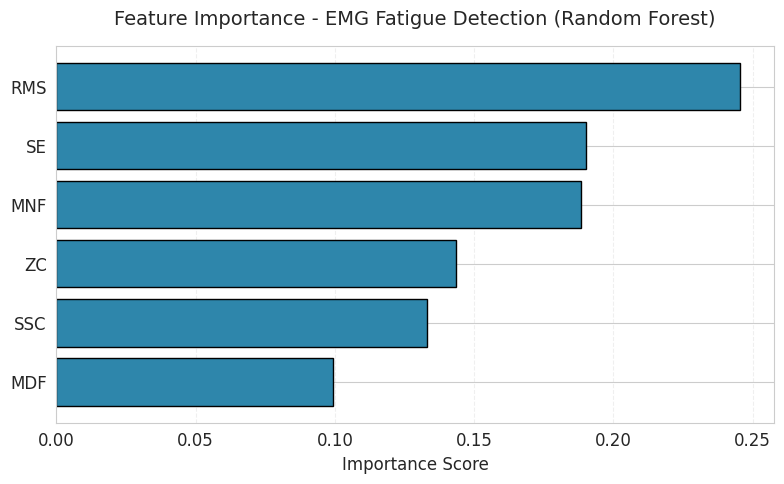

  Feature  Importance
0     RMS       0.245
5      SE       0.190
3     MNF       0.188
1      ZC       0.144
2     SSC       0.133
4     MDF       0.099


In [168]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# IMPORTANT: Retrain on ALL data for visualization only
# Your LOSO F1 0.56 is already valid - this is just for plotting
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # X = features_df[feature_cols].values

rf_full = RandomForestClassifier(
    n_estimators=300, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)
rf_full.fit(X_scaled, y)

# Get importance and sort
feat_imp = pd.DataFrame({
    'Feature': feature_cols, 
    'Importance': rf_full.feature_importances_
}).sort_values('Importance', ascending=True)  # ascending for hbar

# Plot
plt.figure(figsize=(8,5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='#2E86AB', edgecolor='black')
plt.xlabel('Importance Score', fontsize=12)
plt.title('Feature Importance - EMG Fatigue Detection (Random Forest)', fontsize=14, pad=15)
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print(feat_imp.sort_values('Importance', ascending=False).round(3))

cell 25: SUBJECT-WISE PERFORMANCE

In [169]:
from sklearn.metrics import f1_score
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

logo = LeaveOneGroupOut()

subject_scores = []

for train_idx, test_idx in logo.split(X, y, groups):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    test_subject = groups[test_idx][0]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    f1 = f1_score(y_test, y_pred)

    subject_scores.append((test_subject, f1))

subject_df = pd.DataFrame(subject_scores, columns=["Subject", "F1"])
subject_df = subject_df.sort_values("F1")

print(subject_df)

       Subject        F1
6       S07  0.187097
8         S09  0.261954
11     S12  0.272436
12      S13  0.292948
9       S10  0.335260
1     S02  0.339036
3       S04  0.341538
10      S11  0.424779
13        S14  0.456471
7   S08  0.465849
0        S01  0.507109
2        S03  0.513032
5        S06  0.664804
4         S05  0.767591


cell 26

In [170]:
import matplotlib.pyplot as plt
import numpy as np

mean_f1 = subject_df['F1'].mean()
std_f1 = subject_df['F1'].std()

plt.figure(figsize=(12, 6))  # wider figure
bars = plt.bar(subject_df["Subject"], subject_df["F1"], 
               color='#2E86AB', edgecolor='black', alpha=0.8, width=0.6)

# Add mean line
plt.axhline(mean_f1, color='#F18F01', linestyle='--', linewidth=2, 
            label=f'Mean F1 = {mean_f1:.3f} ± {std_f1:.3f}')

# Add value labels on bars
for bar, f1 in zip(bars, subject_df["F1"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015, 
             f'{f1:.2f}', ha='center', va='bottom', fontsize=8)

plt.xticks(rotation=45, ha='right', fontsize=10)  # key fix: rotate + align right
plt.ylabel("F1-score", fontsize=12)
plt.xlabel("Subject", fontsize=12)
plt.title("Leave-One-Subject-Out Performance - Random Forest", fontsize=14, pad=15)
plt.ylim(0, 1.05)  # extra space for labels
plt.legend(loc='upper right', framealpha=0.9)
plt.grid(axis='y', linestyle='--', alpha=0.3)

# Remove the text box - it's now in legend
plt.tight_layout()
plt.savefig('subject_f1.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean F1: {mean_f1:.3f} ± {std_f1:.3f}")

Mean F1: 0.416 ± 0.161


cell 27

In [171]:
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Assumes these exist: features_df, feature_cols, X, y, groups
logo = LeaveOneGroupOut()
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            random_state=42, n_jobs=-1)
}

results = {}

for name, base_model in models.items():
    accs, precs, recs, f1s = [], [], [], []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        model = base_model.__class__(**base_model.get_params())
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        accs.append(accuracy_score(y_test, y_pred))
        precs.append(precision_score(y_test, y_pred, zero_division=0))
        recs.append(recall_score(y_test, y_pred, zero_division=0))
        f1s.append(f1_score(y_test, y_pred, zero_division=0))

    results[name] = {
        'Accuracy': np.mean(accs),
        'Precision': np.mean(precs),
        'Recall': np.mean(recs),
        'F1-score': np.mean(f1s),
        'F1-std': np.std(f1s)
    }

# FINAL MODEL COMPARISON TABLE
comparison = pd.DataFrame(results).T[['Accuracy','Precision','Recall','F1-score']].round(3)
print("="*60)
print("MODEL COMPARISON - 15 SUBJECTS LOSO")
print("="*60)
print(comparison)
print(f"\nRF F1 std: {results['Random Forest']['F1-std']:.3f}")
print(f"LR F1 std: {results['Logistic Regression']['F1-std']:.3f}")

MODEL COMPARISON - 15 SUBJECTS LOSO
                     Accuracy  Precision  Recall  F1-score
Logistic Regression     0.465      0.384   0.640     0.460
Random Forest           0.540      0.483   0.386     0.416

RF F1 std: 0.155
LR F1 std: 0.231


In [172]:
import matplotlib.pyplot as plt

subject_mean = subject_df["F1"].mean()

plt.figure(figsize=(10,5))

plt.bar(subject_df["Subject"], subject_df["F1"],
        color="orange", edgecolor="black")

plt.axhline(subject_mean, linestyle="--", color="black",
            label=f"Mean F1 = {subject_mean:.3f}")

plt.xticks(rotation=45, ha='right')
plt.ylim(0,1)

plt.title("Inter-Subject Variability in EMG Fatigue Classification")
plt.ylabel("F1-score")
plt.legend()

plt.tight_layout()
plt.show()